<div align="center">

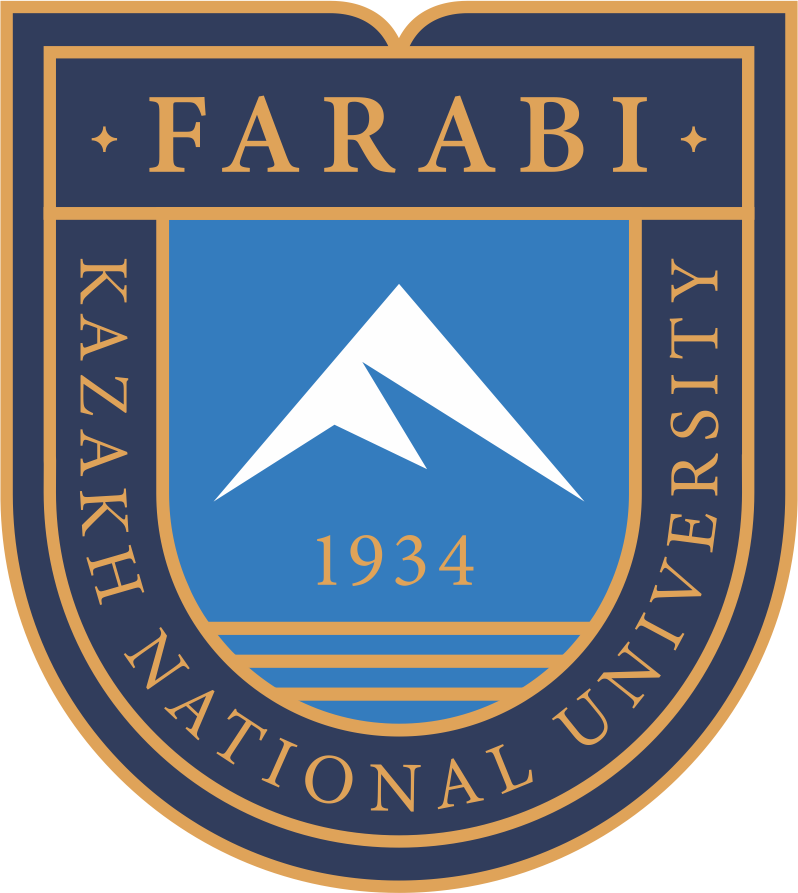

<h2>Al-Farabi Kazakh National University</h2>

<p style="font-size:18px;">
Faculty of Information Technology and Artificial Intelligence<br>
Department of Information Systems
</p>

<br>

<h2 style="color:#1f5678;">
Fundamentals of Dataset Development and Natural Language Processing<br>

</h2>

<br>

<h1>IWS 3</h1>

<hr style="border:1px solid #1f5678; width:85%;">

<p style="font-size:20px;">
Rewriting a Poem with Word Associates (<i>The Road Not Taken</i> by Robert Frost)
</p>

<br>

</div>

<br><br>

<table style="margin-left:auto; margin-right:auto; font-size:17px;">
<tr>
    <td><b>Student:</b></td>
    <td>Zabihullah Anwari</td>
</tr>
<tr>
    <td><b>Year:</b></td>
    <td>2026</td>
</tr>
</table>


# IWS (Indivitual Work of Students) 3  — Independent Assignment: Rewriting a Poem with Word Associates

** What I am supposed to do in this taks; 
 -- take a poem, replace every *content word* (noun, verb, adjective, adverb) with its closest semantic associate from a large pretrained embedding model, keep function words and punctuation unchanged, **keep the grammatical form** of each word, and observe how the meaning changes.

| Step | I have done the following task in this assignment|
|---|---|
| 1. Pretrained model | `fasttext-wiki-news-subwords-300` (FastText, 300 dims, ~1M words, ~16B training tokens, ~958 MB) |
| 2. Preprocessing | lowercase → remove punctuation → split into words |
| 3. Content words | spaCy POS tagging in context; keep `NOUN`, `VERB`, `ADJ`, `ADV`; skip function words |
| 4. Associates | check vocabulary → `model.most_similar(word, topn=1)[0][0]` (plus a filtered top-1, explained below) |
| 5. Replacement | substitute associates, re-inflect them to the original form, keep function words, punctuation and capitalisation |

**Poem:**  
I have chosen the following poem: 
*The Road Not Taken* by Robert Frost (1916, public domain) — 20 lines, 4 stanzas of 5 lines.

## 0. Setup

Libraries used:
- **gensim** — loading the pretrained model and `most_similar`
- **spaCy** (`en_core_web_sm`) — part-of-speech tagging, so we know which words are content words and what grammatical form they have (e.g. `VBD` = past tense verb, `NNS` = plural noun)
- **lemminflect** — turning a word into a given form (`walk` → `walked`), needed for the "keep the form" rule

In [1]:
import re
import pandas as pd
import gensim
import gensim.downloader as api
import spacy
import lemminflect
from lemminflect import getAllLemmas, getInflection

print("gensim     ", gensim.__version__)
print("spaCy      ", spacy.__version__)
print("lemminflect", lemminflect.__version__)

gensim      4.4.0
spaCy       3.8.18
lemminflect 0.2.3


## Step 1. Load a large pretrained model

The class notebook used `glove-wiki-gigaword-50` (50 dimensions). Here we use a much stronger model that still fits in ~1 GB:

| Property | `fasttext-wiki-news-subwords-300` |
|---|---|
| Training data | **~16B tokens** (Wikipedia 2017, UMBC web corpus, statmt.org news) |
| Dimensions | **300** |
| Vocabulary | **~1M** |
| Download | ~958 MB |


In [2]:
# First run downloads ~958 MB into ~/gensim-data; later runs load from the cache
w2v = api.load("fasttext-wiki-news-subwords-300")

print("Vocabulary size:", len(w2v.key_to_index))
print("Vector size:    ", w2v.vector_size)
print("Sanity check, nearest to 'forest':", w2v.most_similar("forest", topn=5))

Vocabulary size: 999999
Vector size:     300
Sanity check, nearest to 'forest': [('forests', 0.8367109894752502), ('forestland', 0.7787671089172363), ('foresty', 0.77434241771698), ('foresting', 0.7735655903816223), ('non-forest', 0.7687437534332275)]


## The poem

In [3]:
poem = """Two roads diverged in a yellow wood,
And sorry I could not travel both
And be one traveler, long I stood
And looked down one as far as I could
To where it bent in the undergrowth;

Then took the other, as just as fair,
And having perhaps the better claim,
Because it was grassy and wanted wear;
Though as for that the passing there
Had worn them really about the same,

And both that morning equally lay
In leaves no step had trodden black.
Oh, I kept the first for another day!
Yet knowing how way leads on to way,
I doubted if I should ever come back.

I shall be telling this with a sigh
Somewhere ages and ages hence:
Two roads diverged in a wood, and I—
I took the one less traveled by,
And that has made all the difference."""

lines = poem.split("\n")                       # keep empty lines = stanza breaks
text_lines = [l for l in lines if l.strip()]
print("Number of lines:", len(text_lines))

Number of lines: 20


## Step 2. Preprocess the poem

Lowercase the text, remove punctuation, split into words.

In [4]:
def preprocess(line):
    line = line.lower()
    line = re.sub(r"[^\w\s']", " ", line)   # punctuation (incl. the dash '—') -> space
    return line.split()

clean_lines = [preprocess(l) for l in text_lines]

for original, words in list(zip(text_lines, clean_lines))[:5]:
    print(f"{original:<45} -> {words}")
print("...")

all_words = [w for ws in clean_lines for w in ws]
print("\nTotal words:", len(all_words), "| unique words:", len(set(all_words)))

Two roads diverged in a yellow wood,          -> ['two', 'roads', 'diverged', 'in', 'a', 'yellow', 'wood']
And sorry I could not travel both             -> ['and', 'sorry', 'i', 'could', 'not', 'travel', 'both']
And be one traveler, long I stood             -> ['and', 'be', 'one', 'traveler', 'long', 'i', 'stood']
And looked down one as far as I could         -> ['and', 'looked', 'down', 'one', 'as', 'far', 'as', 'i', 'could']
To where it bent in the undergrowth;          -> ['to', 'where', 'it', 'bent', 'in', 'the', 'undergrowth']
...

Total words: 144 | unique words: 94


## Step 3. Identify content words

A word list alone cannot tell us the part of speech: *"wood"* is a noun, *"long"* in *"long I stood"* is an adverb, *"lay"* is the past tense of *lie*. So we tag every line **in context** with spaCy (on the original line, because the tagger uses capitalisation and punctuation as clues), and then lowercase the tokens — they are exactly the words from Step 2.

Rules:
- **content word** = POS is `NOUN`, `VERB`, `ADJ` or `ADV`
- **function word** = everything else (determiners, pronouns, prepositions, conjunctions, auxiliaries such as *could / had / shall*, numerals, particles), plus very common grammatical words that spaCy marks as stop words even when tagged `ADV`/`ADJ` (*then, there, as, so, ever, both, other, same…*)

We also record each word's **form** (fine-grained tag such as `VBD`, `NNS`) because Step 5 must keep it. The small spaCy model occasionally mislabels verb forms in poetry (*"it bent"* → present tense), so we double-check the tag against lemminflect's dictionary of real verb forms.

In [5]:
nlp = spacy.load("en_core_web_sm")
CONTENT_POS = {"NOUN", "VERB", "ADJ", "ADV"}

def is_content(tok):
    return tok.pos_ in CONTENT_POS and not tok.is_stop and tok.is_alpha

docs = [nlp(l) for l in text_lines]

# Check: spaCy's alphabetic tokens, lowercased, are the same words as the Step 2 output
for doc, words in zip(docs, clean_lines):
    assert [t.lower_ for t in doc if t.is_alpha] == [w for w in words if w.isalpha()], doc.text

VERB_TAGS = ["VBD", "VBN", "VBZ", "VBG", "VB", "VBP"]

def lemma_and_form(tok):
    # Dictionary lemma + a corrected fine-grained tag.
    # The small spaCy model sometimes gives a verb the wrong form tag in poetry
    # (e.g. 'it bent' -> VBP 'present'). We keep spaCy's tag if the word really is that
    # form of its lemma, otherwise we take the form that lemminflect confirms (bent = VBD of bend).
    word, upos, tag = tok.lower_, tok.pos_, tok.tag_
    if upos not in CONTENT_POS:                 # function words: nothing to check
        return tok.lemma_.lower(), tag
    lemmas = getAllLemmas(word, upos=upos)
    lemma = lemmas[upos][0] if lemmas else tok.lemma_.lower()
    if upos == "VERB" and word not in getInflection(lemma, tag=tag):
        for t in VERB_TAGS:
            if word in getInflection(lemma, tag=t):
                tag = t
                break
    return lemma, tag

rows = []
for i, doc in enumerate(docs, 1):
    for t in doc:
        if t.is_alpha:
            lemma, tag = lemma_and_form(t)
            rows.append({"line": i, "word": t.lower_, "POS": t.pos_, "spacy_tag": t.tag_,
                         "tag": tag, "lemma": lemma, "content": is_content(t)})
pos_df = pd.DataFrame(rows)

content_df = pos_df[pos_df.content]
print("Content words :", len(content_df), "tokens /", content_df.word.nunique(), "unique")
print("Function words:", (~pos_df.content).sum(), "tokens")
print("\nContent words by POS:")
print(content_df.POS.value_counts().to_string())

fixed = content_df[content_df.spacy_tag != content_df.tag]
print("\nForm tags corrected with lemminflect:")
print(fixed[["line", "word", "lemma", "spacy_tag", "tag"]].to_string(index=False) if len(fixed) else "none")

Content words : 47 tokens / 41 unique
Function words: 97 tokens

Content words by POS:
POS
VERB    20
NOUN    18
ADJ      6
ADV      3

Form tags corrected with lemminflect:
 line word lemma spacy_tag tag
    5 bent  bend       VBP VBD


In [6]:
# Content words line by line (function words shown in lowercase grey brackets)
for i, doc in enumerate(docs, 1):
    marked = " ".join(t.text.upper() if is_content(t) else f"[{t.text}]" for t in doc if not t.is_punct)
    print(f"{i:>2}. {marked}")

 1. [Two] ROADS DIVERGED [in] [a] YELLOW WOOD
 2. [And] [sorry] [I] [could] [not] TRAVEL [both]
 3. [And] [be] [one] TRAVELER LONG [I] STOOD
 4. [And] LOOKED [down] [one] [as] FAR [as] [I] [could]
 5. [To] [where] [it] BENT [in] [the] UNDERGROWTH
 6. [Then] TOOK [the] [other] [as] [just] [as] FAIR
 7. [And] HAVING [perhaps] [the] BETTER CLAIM
 8. [Because] [it] [was] GRASSY [and] WANTED WEAR
 9. [Though] [as] [for] [that] [the] PASSING [there]
10. [Had] WORN [them] [really] [about] [the] [same]
11. [And] [both] [that] MORNING EQUALLY LAY
12. [In] LEAVES [no] STEP [had] TRODDEN BLACK
13. [Oh] [I] KEPT [the] [first] [for] [another] DAY
14. [Yet] KNOWING [how] WAY LEADS [on] [to] WAY
15. [I] DOUBTED [if] [I] [should] [ever] COME [back]
16. [I] [shall] [be] TELLING [this] [with] [a] SIGH
17. [Somewhere] AGES [and] AGES [hence]
18. [Two] ROADS DIVERGED [in] [a] WOOD [and] [I]
19. [I] TOOK [the] [one] [less] TRAVELED [by]
20. [And] [that] [has] [made] [all] [the] DIFFERENCE


## Step 4. Find associates

For every content word we check that it is in the model vocabulary and ask for its nearest neighbour:

```python
w2v.most_similar(word, topn=1)[0][0]
```

We record this **raw top-1** for every word. However, on a FastText model the raw top-1 is very often *the same word in another form or spelling* (`roads → road`, `traveled → travelled`, capitalised duplicates such as `Wood`). Replacing a word with itself in a different form would not change the poem at all, so for the actual rewrite we take the **first neighbour (in similarity order) that is a real associate**:

1. lowercase alphabetic word (no `New_York`-style phrases, numbers, or capitalised duplicates);
2. **not the same word**: different lemma, and not a spelling/derivational variant (one word containing the other, e.g. `undergrowth → undergrowths`, `grassy → grass`);
3. **same part of speech**: the candidate must be known to the lemminflect dictionary as the same POS (a verb is replaced by a verb, a noun by a noun) — otherwise the form cannot be kept.

If the raw top-1 already passes these checks, it *is* the chosen associate.

In [7]:
def strip_word(w):
    return re.sub(r"[^a-z]", "", w.lower())

def is_variant(a, b):
    # spelling or derivational variants: one contains the other, or a long shared prefix
    a, b = strip_word(a), strip_word(b)
    if a in b or b in a:
        return True
    k = 0
    while k < min(len(a), len(b)) and a[k] == b[k]:
        k += 1
    return k >= 5 or (k >= 4 and k >= min(len(a), len(b)) - 1)

def candidate_lemma(cand, upos):
    # lemma of the candidate for the given POS from lemminflect's dictionary, or None
    lemmas = getAllLemmas(cand, upos=upos)
    return lemmas[upos][0] if lemmas else None

def find_associate(tok, topn=50):
    word, upos = tok.lower_, tok.pos_
    if word not in w2v.key_to_index:
        return None
    neighbours = w2v.most_similar(word, topn=topn)
    raw_top1, raw_sim = neighbours[0]
    own_lemmas = {word, tok.lemma_.lower(), lemma_and_form(tok)[0]} | {l for ls in getAllLemmas(word).values() for l in ls}
    for rank, (cand, sim) in enumerate(neighbours, 1):
        if not re.fullmatch(r"[a-z]+", cand):
            continue
        lemma = candidate_lemma(cand, upos)
        if lemma is None:
            continue
        if lemma in own_lemmas or any(is_variant(lemma, o) or is_variant(cand, o) for o in own_lemmas):
            continue
        return {"raw_top1": raw_top1, "raw_sim": round(raw_sim, 3),
                "associate": cand, "assoc_lemma": lemma, "rank": rank, "sim": round(sim, 3)}
    return {"raw_top1": raw_top1, "raw_sim": round(raw_sim, 3),
            "associate": None, "assoc_lemma": None, "rank": None, "sim": None}

# Quick demo on a few words
for w in ["wood", "roads", "diverged", "yellow"]:
    t = next(t for d in docs for t in d if t.lower_ == w)
    print(f"{w:<10} raw top-1 = {w2v.most_similar(w, topn=1)[0][0]!r:<14} chosen = {find_associate(t)['associate']!r}")

wood       raw top-1 = 'timber'       chosen = 'timber'
roads      raw top-1 = 'highways'     chosen = 'highways'
diverged   raw top-1 = 'diverge'      chosen = 'differed'
yellow     raw top-1 = 'red'          chosen = 'red'


## Step 5. Replace words — keeping the form

The associate is first reduced to its lemma for the right POS and then **inflected to the original word's tag** with lemminflect:

| Original | Tag | Meaning of the tag | Associate lemma | Inflected |
|---|---|---|---|---|
| *diverged* | `VBD` | past tense | e.g. *converge* | *converged* |
| *roads* | `NNS` | plural noun | e.g. *highway* | *highways* |
| *knowing* | `VBG` | -ing form | e.g. *realize* | *realizing* |

Function words, punctuation, spaces and line breaks are copied unchanged (we rebuild each line from spaCy tokens, which remember their trailing whitespace). Capitalisation is copied from the original word (line-initial words stay capitalised). The same word with the same tag always gets the same replacement (e.g. both occurrences of *roads diverged*).

In [8]:
def inflect(lemma, tag, fallback):
    forms = getInflection(lemma, tag=tag)
    return forms[0] if forms else fallback

def match_case(new, old):
    if old.isupper() and len(old) > 1:
        return new.upper()
    if old[0].isupper():
        return new[0].upper() + new[1:]
    return new

cache, records = {}, []

def replace_token(tok, line_no):
    if not is_content(tok):
        return tok.text_with_ws
    tag = lemma_and_form(tok)[1]                # corrected form tag (see Step 3)
    key = (tok.lower_, tag)
    if key not in cache:
        cache[key] = find_associate(tok)
    info = cache[key]
    if not info or not info["associate"]:
        new = tok.text                          # not in vocabulary / no associate -> keep word
    else:
        new = match_case(inflect(info["assoc_lemma"], tag, info["associate"]), tok.text)
    records.append({"line": line_no, "original": tok.text, "POS": tok.pos_, "tag": tag,
                    "in_vocab": info is not None,
                    "raw_top1": info and info["raw_top1"], "raw_sim": info and info["raw_sim"],
                    "associate": info and info["associate"], "rank": info and info["rank"],
                    "sim": info and info["sim"], "final_form": new})
    return new + tok.whitespace_

new_lines = ["".join(replace_token(t, i) for t in doc) for i, doc in enumerate(docs, 1)]
repl_df = pd.DataFrame(records)

## Result: line by line

In [9]:
for i, (old, new) in enumerate(zip(text_lines, new_lines), 1):
    print(f"Original:  {old}")
    print(f"New:       {new}")
    print()

Original:  Two roads diverged in a yellow wood,
New:       Two highways differed in a red timber,

Original:  And sorry I could not travel both
New:       And sorry I could not trip both

Original:  And be one traveler, long I stood
New:       And be one visitor, wide I sat

Original:  And looked down one as far as I could
New:       And turned down one as much as I could

Original:  To where it bent in the undergrowth;
New:       To where it twisted in the overgrowth;

Original:  Then took the other, as just as fair,
New:       Then went the other, as just as reasonable,

Original:  And having perhaps the better claim,
New:       And getting perhaps the worse assertion,

Original:  Because it was grassy and wanted wear;
New:       Because it was scrubby and liked dress;

Original:  Though as for that the passing there
New:       Though as for that the catching there

Original:  Had worn them really about the same,
New:       Had unlaced them really about the same,

Original:  And both

## Result: the rewritten poem (stanzas kept)

In [10]:
it = iter(new_lines)
rewritten = "\n".join(next(it) if l.strip() else "" for l in lines)
print(rewritten)

Two highways differed in a red timber,
And sorry I could not trip both
And be one visitor, wide I sat
And turned down one as much as I could
To where it twisted in the overgrowth;

Then went the other, as just as reasonable,
And getting perhaps the worse assertion,
Because it was scrubby and liked dress;
Though as for that the catching there
Had unlaced them really about the same,

And both that afternoon similarly rested
In lefts no stride had footsore white.
Oh, I maintained the first for another week!
Yet believing how manner follows on to manner,
I questioned if I should ever go back.

I shall be reminding this with a groan
Somewhere years and years hence:
Two highways differed in a timber, and I—
I went the one less journeyed by,
And that has made all the discrepancy.


## Replacement table

`raw_top1` is the literal `most_similar(word, topn=1)[0][0]`; `associate` is the neighbour actually used (with its `rank` in the neighbour list and cosine similarity `sim`); `final_form` is the associate inflected to the original tag.

In [11]:
pd.set_option("display.max_rows", 200)
repl_df

,line,original,POS,tag,in_vocab,raw_top1,raw_sim,associate,rank,sim,final_form
0,1,roads,NOUN,NNS,True,highways,0.869,highways,1,0.869,highways
1,1,diverged,VERB,VBN,True,diverge,0.792,differed,3,0.736,differed
2,1,yellow,ADJ,JJ,True,red,0.875,red,1,0.875,red
3,1,wood,NOUN,NN,True,timber,0.801,timber,1,0.801,timber
4,2,travel,VERB,VB,True,traveling,0.810,trip,7,0.742,trip
5,3,traveler,NOUN,NN,True,traveller,0.879,visitor,6,0.666,visitor
6,3,long,ADV,RB,True,short,0.792,wide,30,0.651,wide
7,3,stood,VERB,VBD,True,stood-up,0.762,sat,2,0.757,sat
8,4,looked,VERB,VBD,True,loooked,0.800,turned,9,0.733,turned
9,4,far,ADV,RB,True,much,0.733,much,1,0.733,much


In [12]:
n = len(repl_df)
in_vocab = repl_df.in_vocab.sum()
replaced = (repl_df.final_form.str.lower() != repl_df.original.str.lower()).sum()
raw_same = repl_df.apply(lambda r: r.raw_top1 is not None and r.raw_top1 == r.associate, axis=1).sum()

print(f"Content-word tokens:               {n}")
print(f"Found in model vocabulary:         {in_vocab} ({in_vocab/n:.0%})")
print(f"Actually replaced:                 {replaced} ({replaced/n:.0%})")
print(f"Raw top-1 used directly:           {raw_same}")
print(f"Raw top-1 rejected (same word in another form/spelling, other POS, or phrase): {n - raw_same - (n - replaced)}")
print(f"Mean similarity of chosen associate: {repl_df.sim.dropna().mean():.3f}")

Content-word tokens:               47
Found in model vocabulary:         47 (100%)
Actually replaced:                 47 (100%)
Raw top-1 used directly:           13
Raw top-1 rejected (same word in another form/spelling, other POS, or phrase): 34
Mean similarity of chosen associate: 0.740


## Visual comparison: original words vs. their associates

Two plots compare the poem before and after the rewrite:

1. **Embedding map** – every original content word (circle) and its chosen associate (triangle) projected from 300 dimensions to 2 with PCA. The arrow shows *how far the word moved* in the model's space.
2. **Similarity bars** – the cosine similarity between each original word and its associate (the longer the bar, the closer the replacement).

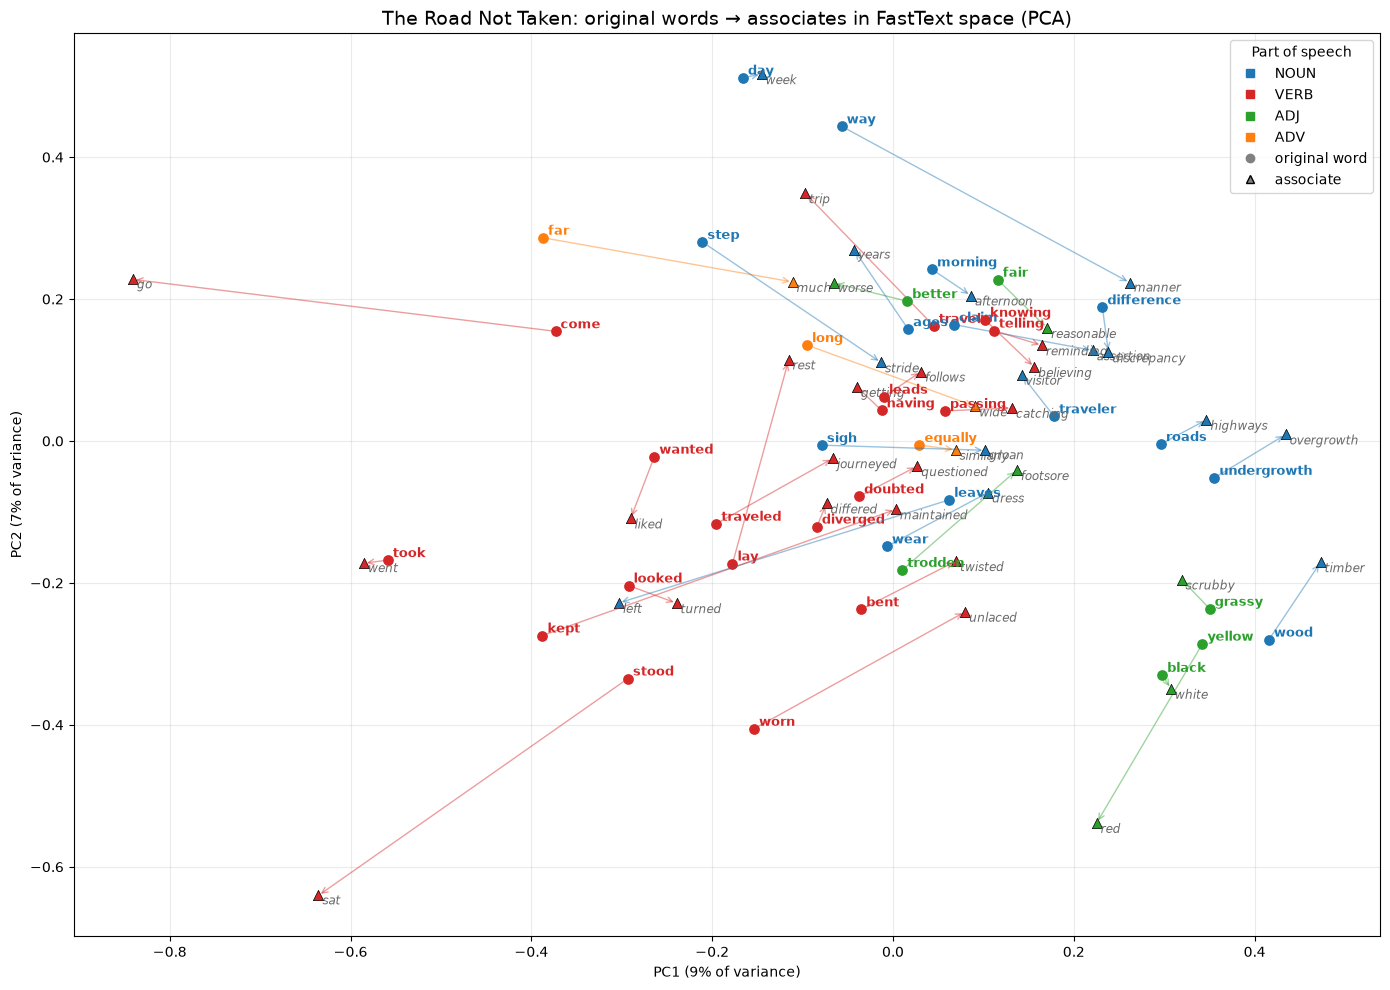

In [13]:
%pip install matplotlib
import numpy as np
import matplotlib.pyplot as plt

# one row per unique (original word, associate) pair
pairs = (repl_df.dropna(subset=["associate"])
         .assign(orig=lambda d: d.original.str.lower())
         .drop_duplicates(subset=["orig", "associate"])
         [["orig", "associate", "POS", "sim"]]
         .reset_index(drop=True))

words = list(pairs.orig) + list(pairs.associate)
X = np.array([w2v[w] for w in words])

# PCA with plain numpy (no extra dependency)
Xc = X - X.mean(axis=0)
U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
XY = Xc @ Vt[:2].T
var = (S[:2] ** 2) / (S ** 2).sum()
n_pairs = len(pairs)
orig_xy, assoc_xy = XY[:n_pairs], XY[n_pairs:]

colors = {"NOUN": "#1f77b4", "VERB": "#d62728", "ADJ": "#2ca02c", "ADV": "#ff7f0e"}
fig, ax = plt.subplots(figsize=(14, 10))
for i, r in pairs.iterrows():
    c = colors[r.POS]
    ax.annotate("", xy=assoc_xy[i], xytext=orig_xy[i],
                arrowprops=dict(arrowstyle="->", color=c, alpha=0.45, lw=1))
    ax.scatter(*orig_xy[i], color=c, marker="o", s=45, zorder=3)
    ax.scatter(*assoc_xy[i], color=c, marker="^", s=55, edgecolor="black", linewidth=0.5, zorder=3)
    ax.text(*orig_xy[i], " " + r.orig, fontsize=9, color=c, weight="bold", va="bottom")
    ax.text(*assoc_xy[i], " " + r.associate, fontsize=8.5, color="dimgray", style="italic", va="top")

handles = [plt.Line2D([], [], marker="s", ls="", color=c, label=p) for p, c in colors.items()]
handles += [plt.Line2D([], [], marker="o", ls="", color="gray", label="original word"),
            plt.Line2D([], [], marker="^", ls="", color="gray", markeredgecolor="black", label="associate")]
ax.legend(handles=handles, loc="best", title="Part of speech")
ax.set_title("The Road Not Taken: original words → associates in FastText space (PCA)", fontsize=14)
ax.set_xlabel(f"PC1 ({var[0]:.0%} of variance)")
ax.set_ylabel(f"PC2 ({var[1]:.0%} of variance)")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

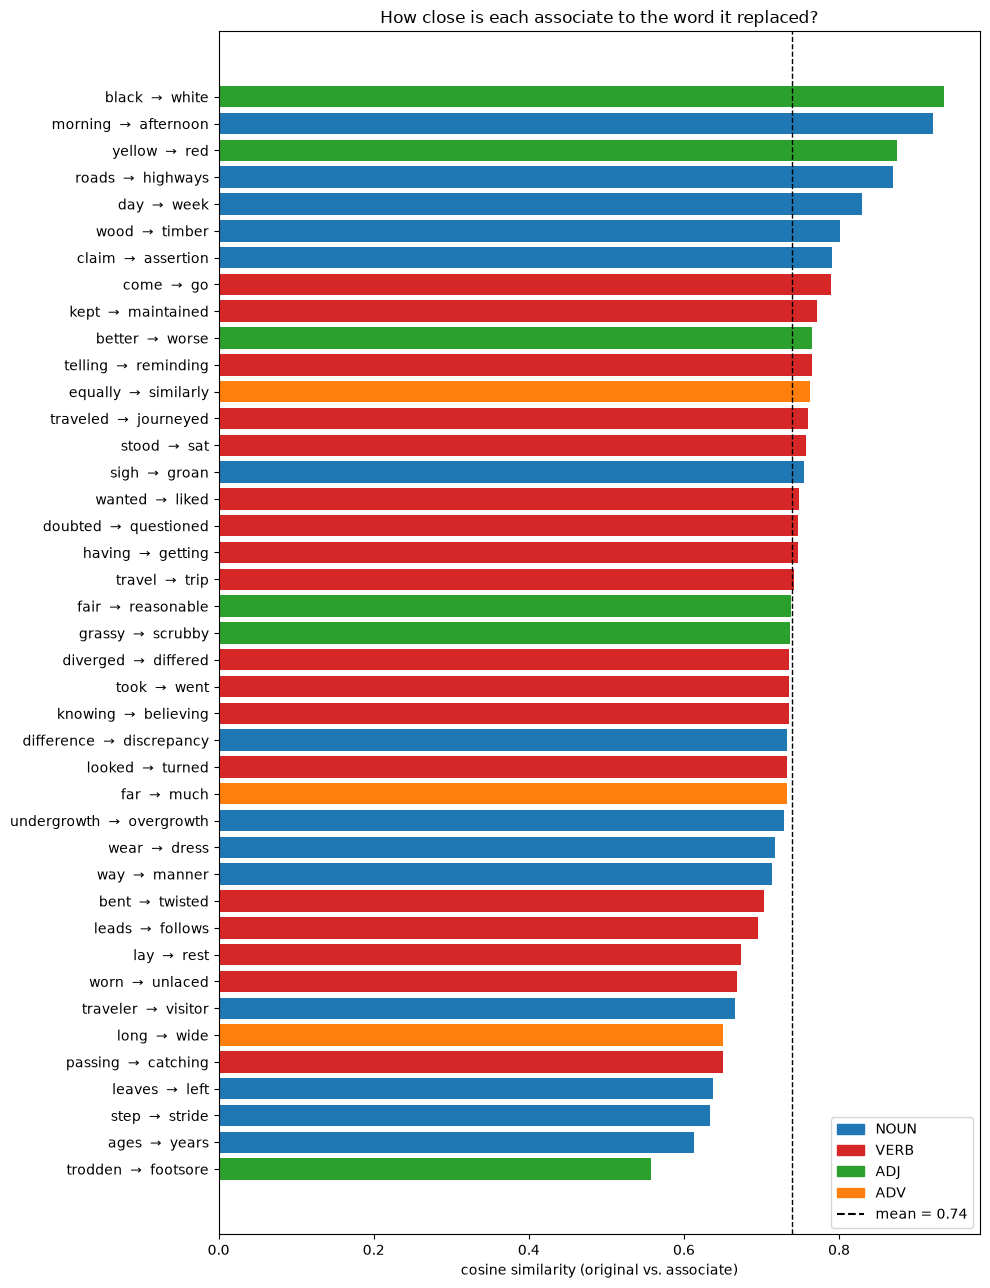

In [14]:
# Similarity of each replacement (sorted)
bars = pairs.sort_values("sim")
fig, ax = plt.subplots(figsize=(10, 0.28 * len(bars) + 1.5))
ax.barh([f"{o}  →  {a}" for o, a in zip(bars.orig, bars.associate)],
        bars.sim, color=[colors[p] for p in bars.POS])
ax.axvline(bars.sim.mean(), color="black", ls="--", lw=1, label=f"mean = {bars.sim.mean():.2f}")
ax.set_xlabel("cosine similarity (original vs. associate)")
ax.set_title("How close is each associate to the word it replaced?")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c, label=p) for p, c in colors.items()]
          + [plt.Line2D([], [], color="black", ls="--", label=f"mean = {bars.sim.mean():.2f}")],
          loc="lower right")
plt.tight_layout()
plt.show()

## Observations

**1. Coverage.** All 47 content-word tokens (41 unique) were in the 1M-word vocabulary and all were replaced; the mean cosine similarity of the chosen associates is ≈ 0.74. Only 13 of the 47 *raw* top-1 neighbours were usable as they are. The other 34 were the same word again:
- another form: *travel → traveling*, *took → taken*, *claim → claims*, *way → ways*, *ages → age*
- a spelling variant or typo: *traveler → traveller*, *looked → loooked*, *better → bettter*, *equally → equaly*, *telling → tellling*, *difference → differnce*
- a phrase or a prefixed word: *stood → stood-up*, *knowing → not-knowing*, *worn → unworn*

This is typical for FastText: it learns from character n-grams, so words that *look* alike end up close together, and the web/news training data contains many typos.

**2. Neighbours are "the same kind of thing", not synonyms.** *yellow → red*, *morning → afternoon*, *day → week*, *ages → years*, *roads → highways*. Word2Vec/FastText place words close when they appear in the same contexts, so colours cluster with colours and time units with time units — they are co-hyponyms, not paraphrases.

**3. Antonyms are neighbours too.** *black → white* (0.935, the most similar pair in the whole poem), *better → worse*, *come → go*, and the raw top-1 of *long* was *short*. Antonyms share almost all their contexts ("a ___ cat", "the ___ claim"), so the distributional hypothesis cannot separate them — exactly the limitation listed in the lecture ("confuses synonyms and antonyms"). This flips the poem's logic: *"the better claim"* becomes *"the worse assertion"*.

**4. One vector per word → the wrong sense is chosen (polysemy).** The model picks the sense that dominates in news text, not the sense in the poem:

| Poem's sense | Associate | Sense the model used |
|---|---|---|
| *wood* = forest | *timber* | wood as a material |
| *leaves* = foliage | *left* | the verb *leave* |
| *passing* = people walking by | *catching* | passing a ball (sports) |
| *wear* = erosion of a path | *dress* | clothing |
| *worn* = worn down | *unlaced* | worn shoes |
| *diverged* = paths splitting | *differed* | opinions differing |
| *difference* = consequence | *discrepancy* | numerical difference |

Static embeddings cannot know the context of the line; contextual models such as BERT (Section 8 of the lecture) give *leaves* a different vector in "autumn leaves" and "she leaves".

**5. What survives.** Syntax, function words, punctuation, stanza structure and grammatical form are kept: *highways* is plural, *twisted* and *rested* are past tense (*lay → rest → rested*), *journeyed* is a past participle. Some lines remain near-paraphrases: *"I doubted if I should ever come back"* → *"I questioned if I should ever go back"*; *kept → maintained*.

**6. What is lost.** The rhyme scheme ABAAB (*wood / both / stood / could / undergrowth*) disappears (*timber / both / sat / could / overgrowth*), and so does the meter. Above all, the central metaphor — the road as a life choice — is gone: the model knows nothing about metaphor, so the poem drifts from a quiet forest scene into the register of its news training data (*highways, assertion, discrepancy, maintained*).

**7. Limitations of the method.** A few replacements are grammatical but odd (*"In lefts no stride had footsore white"*, *"wide I sat"*, *"I could not trip both"*). They come from (a) polysemy (point 4), (b) the small spaCy model tagging *trodden* as an adjective, and (c) top-1 neighbours that fit the word but not the sentence. Choosing among the top-k neighbours using the whole line as context (e.g. a sentence embedding or BERT) would give a more readable poem.

---
# Part 2 
# I found it interesting to do an experimental task in my own language Dari.  
# I did the same process done in English Peom to see how it will work in a peice of poem in my lanaguage. 
# The poem is from (مولانا جلالدین محمد بلخی (Known as Rumi)

The same pipeline applied to a Dari poem. Note: this part re-uses variable names (`poem`, `w2v`, `repl_df`, ...) from Part 1, so run the notebook top to bottom.

## Persian version: Rewriting a Poem with Word Associates

Same task as Section 6 of `class_7.ipynb`, now for **Persian**: replace every *content word* (noun, verb, adjective, adverb) of a poem with its closest semantic associate from a pretrained embedding model, keep function words unchanged, **keep the grammatical form** of each word, and observe how the meaning changes.

| Step | What is done in this notebook |
|---|---|
| 1. Pretrained model | fastText **`cc.fa.300`** (Facebook AI, Common Crawl + Wikipedia), limited to the **200,000 most frequent words** → ~130 MB download, ~240 MB on disk |
| 2. Preprocessing | normalise Arabic/Persian letters, remove diacritics and punctuation, split into words |
| 3. Content words | skip function words: spaCy's Persian stop-word list + archaic/poetic function words |
| 4. Associates | check vocabulary → `w2v.most_similar(word, topn=1)[0][0]` (plus a filtered top-1, explained below) |
| 5. Replacement | substitute associates and rebuild Persian word forms (plural ‌ها / ان, verb prefixes ب / ن / می‌, person endings, perfect tense ‌اند, ezafe ٔ) |

**Poem:** the opening of Rumi's *Masnavi* («نی‌نامه», 13th century, public domain) — 10 couplets = 20 hemistichs, one per line.

**Why Persian is harder than English here:** there is no Persian POS tagger or inflection library in our environment (spaCy only ships a Persian stop-word list), words are written with a zero-width non-joiner (ZWNJ, «نیم‌فاصله») inside them (*می‌کند*, *جدایی‌ها*), and the same word is often written in several ways (*آتش / اتش*, Arabic *ي* vs Persian *ی*).

## 0. Setup

In [15]:
import os, re, gzip, time, urllib.request
import numpy as np
import pandas as pd
import gensim
from gensim.models import KeyedVectors
from spacy.lang.fa.stop_words import STOP_WORDS    # Persian stop-word list shipped with spaCy

print("gensim", gensim.__version__, "| Persian stop words:", len(STOP_WORDS))

gensim 4.4.0 | Persian stop words: 389


## Step 1. Load a pretrained Persian model (light version)

`gensim.downloader` has no Persian model, so we use the official fastText vectors **`cc.fa.300`** (Grave et al., 2018): 300-dimensional vectors trained on Persian Common Crawl and Wikipedia.

The full file has 2,000,000 words and is 1.26 GB. The words in the file are **sorted by frequency**, so we stream only the first **200,000 words** directly from the server (no full download), save them once in gensim's `KeyedVectors` format, and load that small file in later runs.

| | full `cc.fa.300` | **used here** |
|---|---|---|
| Vocabulary | 2,000,000 | **200,000** most frequent words |
| Download | 1.26 GB | **~130 MB** (streamed) |
| On disk / RAM | ~2.4 GB | **~240 MB** |

The loaded object is a `KeyedVectors`, so methods are called directly (`w2v.most_similar(...)`, no `.wv`).

In [16]:
URL = "https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.fa.300.vec.gz"
N_WORDS = 200_000
CACHE = os.path.join(os.path.expanduser("~"), "gensim-data", "cc.fa.300-200k", "cc.fa.300-200k.kv")

def build_light_model(url=URL, n=N_WORDS, path=CACHE):
    # Stream the first n vectors of the fastText .vec.gz file and save them as KeyedVectors
    os.makedirs(os.path.dirname(path), exist_ok=True)
    keys, vecs = [], np.zeros((n, 300), dtype=np.float32)
    with urllib.request.urlopen(url) as resp, gzip.GzipFile(fileobj=resp) as gz:
        gz.readline()                                        # header: "2000000 300"
        for i in range(n):
            parts = gz.readline().decode("utf-8").rstrip().split(" ")
            keys.append(parts[0])
            vecs[i] = np.asarray(parts[1:301], dtype=np.float32)
    kv = KeyedVectors(vector_size=300)
    kv.add_vectors(keys, vecs)
    kv.save(path)

if not os.path.exists(CACHE):
    t0 = time.time()
    build_light_model()
    print(f"Downloaded and saved in {time.time() - t0:.0f} s")

w2v = KeyedVectors.load(CACHE)
print("Vocabulary size:", len(w2v.key_to_index))
print("Vector size:    ", w2v.vector_size)
print("Sanity check, nearest to 'عشق':", w2v.most_similar("عشق", topn=5))

Vocabulary size: 200000
Vector size:     300
Sanity check, nearest to 'عشق': [('وعشق', 0.6374408006668091), ('محبت', 0.6194408535957336), ('عاشقی', 0.6102855801582336), ('عشق\u200c', 0.5989023447036743), ('عشقی', 0.5935357213020325)]


## The poem

Rumi, *Masnavi*, Book I, lines 1–10 (*Nicholson / Estelami* reading «بشنو این نی چون شکایت می‌کند»). Short English paraphrase of each couplet:

1. Listen to this reed as it complains, telling the story of separations:
2. "Since they cut me from the reed-bed, men and women have wept in my cry.
3. I want a chest torn to pieces by separation, so that I can tell the pain of longing.
4. Everyone who is left far from his origin seeks again the time of union with it.
5. In every gathering I lamented; I was a companion of the unhappy and the happy.
6. Everyone became my friend by his own guess; no one searched for my secrets within me.
7. My secret is not far from my lament, but eye and ear do not have that light.
8. Body is not hidden from soul nor soul from body, yet no one is permitted to see the soul.
9. This sound of the reed is fire, not wind; whoever lacks this fire, may he be nothing!
10. It is the fire of love that fell into the reed; it is the ferment of love that fell into the wine.

In [17]:
poem = """بشنو این نی چون شکایت می‌کند
از جدایی‌ها حکایت می‌کند
کز نیستان تا مرا ببریده‌اند
در نفیرم مرد و زن نالیده‌اند
سینه خواهم شرحه شرحه از فراق
تا بگویم شرح درد اشتیاق
هر کسی کو دور ماند از اصل خویش
باز جوید روزگار وصل خویش
من به هر جمعیتی نالان شدم
جفت بدحالان و خوش‌حالان شدم
هر کسی از ظن خود شد یار من
از درون من نجست اسرار من
سر من از نالهٔ من دور نیست
لیک چشم و گوش را آن نور نیست
تن ز جان و جان ز تن مستور نیست
لیک کس را دید جان دستور نیست
آتش است این بانگ نای و نیست باد
هر که این آتش ندارد نیست باد
آتش عشق است کاندر نی فتاد
جوشش عشق است کاندر می فتاد"""


lines = [l for l in poem.split("\n") if l.strip()]
print("Number of lines (hemistichs):", len(lines))

Number of lines (hemistichs): 20


## Step 2. Preprocess the poem

Lowercasing does not exist in Persian script, so the equivalent normalisation is:
- unify Arabic and Persian letter variants (*ي → ی*, *ك → ک*, *ة → ه*), so the same word always has the same spelling;
- remove short-vowel diacritics (*harakat*);
- remove punctuation (Persian ، ؛ ؟ and Latin), **keeping** the ZWNJ and the ezafe hamza because they are part of the word (*می‌کند*, *نالهٔ*);
- split into words on spaces.

In [18]:
ZWNJ = "‌"        # zero-width non-joiner (نیم‌فاصله), e.g. می‌کند, جدایی‌ها
HAMZA = "ٔ"       # small hamza above, e.g. نالهٔ (ezafe)
ARABIC_TO_PERSIAN = str.maketrans({"ي": "ی", "ك": "ک", "ى": "ی", "ة": "ه", "ۀ": "ه" + HAMZA})
PERSIAN_LETTERS = set("آابپتثجچحخدذرزژسشصضطظعغفقکگلمنوهیئ") | {ZWNJ, HAMZA}

def normalize(word):
    # Unify Arabic/Persian letter variants and remove diacritics (harakat)
    word = word.translate(ARABIC_TO_PERSIAN)
    return re.sub(r"[ً-ْ]", "", word)

def preprocess(line):
    line = normalize(line)
    line = re.sub(r"[^\w\s" + ZWNJ + HAMZA + r"]", " ", line)   # remove punctuation ، ؛ ؟ ! . etc.
    return line.split()


clean_lines = [preprocess(l) for l in lines]
for original, words in list(zip(lines, clean_lines))[:4]:
    print(original, " ->", words)
print("...")

all_words = [w for ws in clean_lines for w in ws]
print("\nTotal words:", len(all_words), "| unique words:", len(set(all_words)))

بشنو این نی چون شکایت می‌کند  -> ['بشنو', 'این', 'نی', 'چون', 'شکایت', 'می\u200cکند']
از جدایی‌ها حکایت می‌کند  -> ['از', 'جدایی\u200cها', 'حکایت', 'می\u200cکند']
کز نیستان تا مرا ببریده‌اند  -> ['کز', 'نیستان', 'تا', 'مرا', 'ببریده\u200cاند']
در نفیرم مرد و زن نالیده‌اند  -> ['در', 'نفیرم', 'مرد', 'و', 'زن', 'نالیده\u200cاند']
...

Total words: 128 | unique words: 82


## Step 3. Identify content words

There is no Persian POS tagger available in our environment, so we identify content words **by excluding function words** — which in Persian is a closed, listable class:

- **spaCy's Persian stop-word list** (389 words): prepositions (*از، به، در، تا*), conjunctions (*و، که، چون*), pronouns (*من، این، آن، خود، خویش*), the object marker *را*, the copula (*است، نیست*), auxiliaries and the verbal prefix *می*, etc.
- plus **archaic/poetic function words** of classical poetry that the modern list does not contain: contractions (*کز = که+از*, *کو = که+او*, *کاندر = که+اندر*), archaic prepositions (*ز، اندر*), *لیک* (= but), *مرا* (= من+را), and the copula/light verb *شدم* (as in *نالان شدم* "I became lamenting") — they play the role of English auxiliaries.

Everything else written in Persian letters is a content word (noun, verb, adjective or adverb).

In [19]:
POETIC_FUNCTION_WORDS = {
    "ز", "اندر", "لیک", "لیکن",          # archaic forms of از / در / ولی
    "کز", "کو", "کاندر", "کین", "کان",   # contractions: که+از, که+او, که+اندر, که+این, که+آن
    "مرا", "ترا", "کس",                  # pronoun forms: من+را, تو+را, کس = anyone
    "شدم", "شدی", "شدند", "بود", "بودم", "هست", "هستم",   # copula / light verbs (like English auxiliaries)
    "چو", "گر", "ور", "وز", "همی", "زین", "زان", "نه",    # archaic conjunctions / particles
}
FUNCTION_WORDS = set(STOP_WORDS) | POETIC_FUNCTION_WORDS

def is_content(word):
    return word not in FUNCTION_WORDS and all(ch in PERSIAN_LETTERS for ch in word)


rows = []
for i, words in enumerate(clean_lines, 1):
    for w in words:
        rows.append({"line": i, "word": w, "content": is_content(w)})
words_df = pd.DataFrame(rows)

content_df = words_df[words_df.content]
print("Content words :", len(content_df), "tokens /", content_df.word.nunique(), "unique")
print("Function words:", (~words_df.content).sum(), "tokens\n")
for i, words in enumerate(clean_lines, 1):
    print(f"{i:>2}.", " ".join(w if is_content(w) else f"[{w}]" for w in words))

Content words : 60 tokens / 50 unique
Function words: 68 tokens

 1. بشنو [این] نی [چون] شکایت [می‌کند]
 2. [از] جدایی‌ها حکایت [می‌کند]
 3. [کز] نیستان [تا] [مرا] ببریده‌اند
 4. [در] نفیرم مرد [و] زن نالیده‌اند
 5. سینه خواهم شرحه شرحه [از] فراق
 6. [تا] بگویم شرح درد اشتیاق
 7. [هر] [کسی] [کو] [دور] ماند [از] اصل [خویش]
 8. [باز] جوید روزگار وصل [خویش]
 9. [من] [به] [هر] جمعیتی نالان [شدم]
10. جفت بدحالان [و] خوش‌حالان [شدم]
11. [هر] [کسی] [از] ظن [خود] [شد] یار [من]
12. [از] [درون] [من] نجست اسرار [من]
13. سر [من] [از] نالهٔ [من] [دور] [نیست]
14. [لیک] چشم [و] گوش [را] [آن] نور [نیست]
15. تن [ز] جان [و] جان [ز] تن مستور [نیست]
16. [لیک] [کس] [را] دید جان دستور [نیست]
17. آتش [است] [این] بانگ نای [و] [نیست] باد
18. [هر] [که] [این] آتش [ندارد] [نیست] باد
19. آتش عشق [است] [کاندر] نی فتاد
20. جوشش عشق [است] [کاندر] [می] فتاد


### Word forms (needed for "keep the form")

Persian marks grammar with prefixes and suffixes. Without a morphological analyser we use a few **orthographic rules**, and accept a split only if the remaining stem is itself a word of the model (so *جان* is not split into *ج + ان*, and *چشم* is not *چش + م*):

| Rule | Example | Split |
|---|---|---|
| ezafe with hamza | نالهٔ | ناله + ٔ |
| suffix after ZWNJ (plural, perfect tense, …) | جدایی‌ها, نالیده‌اند | جدایی + ‌ها, نالیده + ‌اند |
| plural -ان | بدحالان | بدحال + ان |
| person ending / possessive -م, indefinite -ی | بگویم, نفیرم, جمعیتی | بگوی + م, نفیر + م, جمعیت + ی |
| verbal prefix می‌ / نمی‌ / ب- / ن- | بگویم, ببریده‌اند, نجست | ب + گوی + م, ب + بریده + ‌اند, ن + جست |

The prefix rule for *ب-/ن-* is only applied when no noun suffix was found and the remaining stem is among the **20,000 most frequent** words (*جست* rank 6,413, *گوی* 7,735, *بریده* 11,674) — otherwise *نیستان* (reed-bed) would become *ن + یست + ان*, and *نفیرم* ("my cry") would become *ن + فیر + م*. Plural *-ان* and the endings *-م / -ی* only need the stem to be in the 200k vocabulary.

In [20]:
ZWNJ_SUFFIXES = {"ها", "های", "هایی", "اند", "ام", "ای", "ایم", "اید", "است", "تر", "ترین"}
PERFECT_SUFFIXES = {ZWNJ + s for s in ("اند", "ام", "ای", "ایم", "اید", "است")}   # نالیده‌اند = past participle + ‌اند
FREQ_LIMIT = 50_000      # "frequent word" = among the 50k most frequent words of the model
PREFIX_LIMIT = 20_000    # a verb stem after removing ب-/ن- must be among the 20k most frequent words

def in_vocab(w):
    return w in w2v.key_to_index

def frequent(w, limit=FREQ_LIMIT):
    return w2v.key_to_index.get(w, limit) < limit

def analyse(word, strict=False):
    # Split a Persian word into (prefix, stem, suffix) with a few orthographic rules.
    # Every split is accepted only if the remaining stem is itself a word of the model,
    # which protects words like جان (not ج + ان) or چشم (not چش + م).
    # strict=True (used for candidate neighbours) demands that the stem is a *frequent* word,
    # so that lexical words such as هجران are not mistaken for "هجر + plural ان".
    check = frequent if strict else in_vocab
    prefix, stem, suffix = "", word, ""
    # 1. ezafe written with hamza:  نالهٔ -> ناله + ٔ
    if stem.endswith(HAMZA):
        stem, suffix = stem[:-1], HAMZA
    # 2. suffix attached with a ZWNJ:  جدایی‌ها -> جدایی + ‌ها ,  ببریده‌اند -> ببریده + ‌اند
    elif ZWNJ in stem and stem.rsplit(ZWNJ, 1)[1] in ZWNJ_SUFFIXES:
        left, right = stem.rsplit(ZWNJ, 1)
        stem, suffix = left, ZWNJ + right
    # 3. plural -ان:  بدحالان -> بدحال + ان
    elif stem.endswith("ان") and len(stem) >= 5 and check(stem[:-2]):
        stem, suffix = stem[:-2], "ان"
    # 4. person ending / possessive -م, indefinite -ی:  بگویم -> بگوی + م ,  جمعیتی -> جمعیت + ی
    elif stem[-1:] in ("م", "ی") and len(stem) >= 4 and check(stem[:-1]) and stem[:-1] not in FUNCTION_WORDS:
        stem, suffix = stem[:-1], stem[-1]
    # 5. verbal prefixes:  می‌/نمی‌ (with ZWNJ), or ب-/ن- (subjunctive, imperative, negation).
    #    ب-/ن- are only verbal when no noun suffix was found and the rest is a frequent word.
    for p in ("نمی" + ZWNJ, "می" + ZWNJ):
        if stem.startswith(p):
            return p, stem[len(p):], suffix
    if (stem[:1] in ("ب", "ن") and len(stem) >= 4 and stem[1] not in "اآ"
            and suffix in {"", "م"} | PERFECT_SUFFIXES and frequent(stem[1:], PREFIX_LIMIT)):
        prefix, stem = stem[0], stem[1:]
    return prefix, stem, suffix

def is_past(w):
    # past-tense verb form (3rd person singular / past stem) ends in -د or -ت:  نالید، جست، گریست
    return w[-1:] in ("د", "ت")

def is_infinitive(w):
    # infinitives (verbal nouns) end in -دن / -تن:  شنیدن، جستن
    return len(w) >= 4 and w.endswith(("دن", "تن"))

def compose(prefix, stem, suffix):
    # Put a (new) stem back into the original's form, following Persian spelling rules
    w = prefix + stem
    if not suffix:
        return w
    if suffix == HAMZA:                      # ezafe: written as ٔ only after silent ه
        return w + HAMZA if w.endswith("ه") else w
    if suffix.startswith(ZWNJ):              # ‌ها ‌اند ‌ام ... always with ZWNJ
        return w + suffix
    if suffix == "ان" and w.endswith("ه"):   # ستاره -> ستارگان
        return w[:-1] + "گان"
    if suffix in ("ی", "م") and w.endswith("ه"):           # خانه + ی -> خانه‌ای , خانه + م -> خانه‌ام
        return w + ZWNJ + "ا" + suffix
    if suffix in ("ی", "م") and w.endswith(("ا", "و")):    # دریا + ی -> دریایی , مو + م -> مویم
        return w + "ی" + suffix
    return w + suffix


form_rows = []
for w in dict.fromkeys(content_df.word):
    p, s, x = analyse(w)
    if p or x:
        form_rows.append({"word": w, "prefix": p, "stem": s, "suffix": x.replace(ZWNJ, "‌")})
pd.DataFrame(form_rows)

,word,prefix,stem,suffix
0,جدایی‌ها,,جدایی,‌ها
1,نیستان,,نیست,ان
2,ببریده‌اند,ب,بریده,‌اند
3,نفیرم,,نفیر,م
4,نالیده‌اند,,نالیده,‌اند
5,خواهم,,خواه,م
6,بگویم,ب,گوی,م
7,جمعیتی,,جمعیت,ی
8,نالان,,نال,ان
9,بدحالان,,بدحال,ان


## Step 4. Find associates

For every content word we check that it is in the vocabulary. Rare inflected forms are looked up through their stem (*نفیرم → نفیر*, *ببریده‌اند → بریده*), and a perfect tense with a rare participle through its past form (*نالیده‌اند → نالید*). Then we take the nearest neighbour:

```python
w2v.most_similar(word, topn=1)[0][0]
```

This **raw top-1** is recorded for every word. As in the English version, it is very often the same word again: another spelling (*ني* with Arabic ي, *اتش* without madda), another form (*شکایتی, جانش, دستورات*), or the word glued to a neighbour (*وعشق* = و+عشق). Common Crawl also contains junk tokens. So for the actual rewrite we take the **first neighbour that is a real associate**:

1. among the **50,000 most frequent words** (`restrict_vocab=50000`) — removes junk tokens and glued words;
2. written in Persian letters and not a function word;
3. **not the same word**: not containing/contained in the original, not differing by one letter (*چشم ~ جشم*, *جوید ~ جویند*), and spelling differences ignored (*آتش ~ اتش*);
4. a past verb is replaced by a past verb (*نجست, نالیده‌اند*), and an infinitive is not used for a noun or a finite verb.

In [21]:
def plain(w):
    # spelling-insensitive form used only for comparing words:  آتش ~ اتش ,  جدائی ~ جدایی
    w = w.replace(ZWNJ, "").replace(HAMZA, "").replace("ـ", "")
    return w.translate(str.maketrans({"آ": "ا", "أ": "ا", "إ": "ا", "ئ": "ی", "ؤ": "و"}))

def edit_distance(a, b):
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]

def is_variant(a, b):
    # same word in another form or spelling: one contains the other (عشق ~ وعشق, جان ~ جانش),
    # a long shared beginning (حکایت ~ حکایتی), or a one-letter difference / typo (چشم ~ جشم, جوید ~ جویند)
    a, b = plain(a), plain(b)
    if len(a) >= 2 and len(b) >= 2 and (a in b or b in a):
        return True
    if min(len(a), len(b)) >= 3 and edit_distance(a, b) <= 1:
        return True
    k = 0
    while k < min(len(a), len(b)) and a[k] == b[k]:
        k += 1
    return k >= 4

def lookup_key(word):
    # Which vocabulary entry represents the word, and which affixes must be put back afterwards:
    #   'word'  - the word itself (or without ZWNJ / hamza)
    #   'stem'  - its stem, for rare inflected forms:  نفیرم -> نفیر (+م) ,  ببریده‌اند -> ب + بریده + ‌اند
    #   'past'  - for a perfect tense whose participle is rare, the past form:  نالیده‌اند -> نالید
    prefix, stem, suffix = analyse(word)
    for key in (word, word.replace(ZWNJ, ""), word.replace(HAMZA, "")):
        if in_vocab(key):
            return key, "word", prefix, stem, suffix
    if prefix and in_vocab(prefix + stem):          # keep the prefix inside the stem if that word exists
        return prefix + stem, "stem", "", prefix + stem, suffix
    if in_vocab(stem):
        return stem, "stem", prefix, stem, suffix
    if suffix in PERFECT_SUFFIXES and stem.endswith("ه") and in_vocab(stem[:-1]):
        return stem[:-1], "past", prefix, stem, suffix
    return None, None, prefix, stem, suffix

def find_associate(word, topn=100):
    key, how, prefix, stem, suffix = lookup_key(word)
    if key is None:
        return None                                    # not in the vocabulary -> word is kept
    # the literal instruction: top-1 neighbour in the whole vocabulary
    raw_top1, raw_sim = w2v.most_similar(key, topn=1)[0]
    # candidates for the rewrite: only frequent words (removes Common Crawl junk such as glued tokens)
    neighbours = w2v.most_similar(key, topn=topn, restrict_vocab=FREQ_LIMIT)
    needs_past = how == "past" or (prefix in ("ب", "ن") and is_past(stem))
    candidates = []
    for rank, (cand, sim) in enumerate(neighbours, 1):
        cand = normalize(cand)
        if not is_content(cand) or len(plain(cand)) < 2:
            continue                                   # not Persian / function word / noise
        c_prefix, c_stem, c_suffix = analyse(cand, strict=True)
        if any(is_variant(x, y) for x in (cand, c_stem) for y in (word, stem, key)):
            continue                                   # the same word in another form or spelling
        if needs_past and not is_past(cand):
            continue                                   # a past verb must be replaced by a past verb
        if is_infinitive(cand) and not is_infinitive(key):
            continue                                   # do not turn a noun/finite verb into an infinitive
        candidates.append((rank, cand, sim, (c_prefix, c_suffix), c_stem))
    result = {"key": key, "lookup": how, "raw_top1": raw_top1, "raw_sim": round(raw_sim, 3)}
    if not candidates:
        return {**result, "associate": None, "rank": None, "sim": None, "form": "kept", "final": word}

    signature = (prefix, suffix)
    if how == "past":                                  # نالیده‌اند -> (گریست) -> گریسته‌اند
        rank, cand, sim, _, _ = candidates[0]
        final, form = prefix + cand + "ه" + suffix, "rebuilt"
    elif how == "stem":                                # the stem was looked up -> put the affixes back
        plain_cands = [c for c in candidates if c[3] == ("", "")] or candidates
        rank, cand, sim, _, c_stem = plain_cands[0]
        final, form = compose(prefix, c_stem, suffix), "rebuilt"
    elif signature == ("", ""):
        # plain word: nothing to keep, but do not add a verbal prefix that changes the meaning
        # (e.g. ماند must not become the negated نگذاشت)
        no_prefix = [c for c in candidates if c[3][0] == ""] or candidates
        rank, cand, sim, _, _ = no_prefix[0]
        final, form = cand, "same form"
    else:
        # prefer a neighbour that already has the same affixes, otherwise rebuild the best one
        same_form = [c for c in candidates if c[3] == signature]
        if same_form:                                  # a neighbour that already has the same affixes
            rank, cand, sim, _, _ = same_form[0]
            final, form = cand, "same form"
        else:                                          # best neighbour, rebuilt into the original's form
            rank, cand, sim, _, c_stem = candidates[0]
            final, form = compose(prefix, c_stem, suffix), "rebuilt"
    return {**result, "associate": cand, "rank": rank, "sim": round(sim, 3), "form": form, "final": final}


# demo
for w in ["نی", "آتش", "نالان", "عشق"]:
    print(f"{w:<8} raw top-1 = {w2v.most_similar(w, topn=1)[0][0]:<10} chosen = {find_associate(w)['associate']}")

نی       raw top-1 = ني         chosen = دف
آتش      raw top-1 = اتش        chosen = شعله
نالان    raw top-1 = گریان      chosen = گریان
عشق      raw top-1 = وعشق       chosen = محبت


## Step 5. Replace words — keeping the form

The form is kept in one of two ways:
- **same form** — a neighbour that already has the original's affixes is preferred (*خواهم → توانم*: both "I + verb"; *بگویم → بدانم*: both subjunctive 1st person), and a plain word is never replaced by a word with a verbal prefix (so *ماند* "stayed" cannot become a negated verb);
- **rebuilt** — otherwise the neighbour's stem gets the original's prefix and suffix back, following Persian spelling rules: ‌ها and ‌اند are attached with a ZWNJ, plural *-ان* after silent ه becomes *-گان* (*ستاره → ستارگان*), the ezafe hamza is written only after silent ه, the perfect tense is *past stem + ه + ‌اند*.

Function words are copied unchanged, and the same word always gets the same replacement (*آتش* appears three times).

In [22]:
cache, records = {}, []

for i, words in enumerate(clean_lines, 1):
    for w in words:
        if not is_content(w):
            continue
        if w not in cache:
            cache[w] = find_associate(w)
        r = cache[w]
        prefix, stem, suffix = analyse(w)
        records.append({"line": i, "original": w, "affixes": f"{prefix}+…+{suffix}".replace(ZWNJ, "") if (prefix or suffix) else "",
                        "in_vocab": r is not None, "lookup": r and r["lookup"],
                        "raw_top1": r and r["raw_top1"], "raw_sim": r and r["raw_sim"],
                        "associate": r and r["associate"], "rank": r and r["rank"], "sim": r and r["sim"],
                        "form": r["form"] if r else "kept (OOV)", "final": r["final"] if r else w})

def rewrite(words):
    return " ".join(cache[w]["final"] if is_content(w) and cache.get(w) else w for w in words)

new_lines = [rewrite(words) for words in clean_lines]
repl_df = pd.DataFrame(records)

## Result: line by line

In [23]:
for old, new in zip(lines, new_lines):
    print("Original: ", old)
    print("New:      ", new)
    print()

Original:  بشنو این نی چون شکایت می‌کند
New:       مکن این دف چون شاکی می‌کند

Original:  از جدایی‌ها حکایت می‌کند
New:       از دوری‌ها حاکی می‌کند

Original:  کز نیستان تا مرا ببریده‌اند
New:       کز چناران تا مرا بکشیده‌اند

Original:  در نفیرم مرد و زن نالیده‌اند
New:       در حلزونم زن و مرد گریسته‌اند

Original:  سینه خواهم شرحه شرحه از فراق
New:       پستان توانم جبال جبال از هجران

Original:  تا بگویم شرح درد اشتیاق
New:       تا بدانم ذیل سوزش شوق

Original:  هر کسی کو دور ماند از اصل خویش
New:       هر کسی کو دور باقی از اساسی خویش

Original:  باز جوید روزگار وصل خویش
New:       باز کوشید دوران متصل خویش

Original:  من به هر جمعیتی نالان شدم
New:       من به هر جغرافیایی گریان شدم

Original:  جفت بدحالان و خوش‌حالان شدم
New:       لونه مریضان و خرسندان شدم

Original:  هر کسی از ظن خود شد یار من
New:       هر کسی از سو خود شد دیرین من

Original:  از درون من نجست اسرار من
New:       از درون من نجوید راز من

Original:  سر من از نالهٔ من دور نیست
New:       پا من از گریهٔ من دور

## Result: the rewritten poem (couplets)

In [24]:
for k in range(0, len(new_lines), 2):
    print(new_lines[k], "   ***   ", new_lines[k + 1])

مکن این دف چون شاکی می‌کند    ***    از دوری‌ها حاکی می‌کند
کز چناران تا مرا بکشیده‌اند    ***    در حلزونم زن و مرد گریسته‌اند
پستان توانم جبال جبال از هجران    ***    تا بدانم ذیل سوزش شوق
هر کسی کو دور باقی از اساسی خویش    ***    باز کوشید دوران متصل خویش
من به هر جغرافیایی گریان شدم    ***    لونه مریضان و خرسندان شدم
هر کسی از سو خود شد دیرین من    ***    از درون من نجوید راز من
پا من از گریهٔ من دور نیست    ***    لیک پلک و شنوایی را آن تابش نیست
هزار ز باخته و باخته ز هزار پنهان نیست    ***    لیک کس را نگریست باخته فرمان نیست
شعله است این نعره گلو و نیست وزش    ***    هر که این شعله ندارد نیست وزش
شعله محبت است کاندر دف غمت    ***    فوران محبت است کاندر می غمت


## Replacement table

`raw_top1` is the literal `most_similar(word, topn=1)[0][0]` over the whole 200k vocabulary; `associate` is the neighbour actually used, with its `rank` among the 50k-word neighbours and its cosine similarity `sim`; `form` says whether the associate already had the right form or was rebuilt; `final` is what appears in the new poem.

In [25]:
pd.set_option("display.max_rows", 200)
repl_df

,line,original,affixes,in_vocab,lookup,raw_top1,raw_sim,associate,rank,sim,form,final
0,1,بشنو,,True,word,بشنوی,0.523,مکن,1,0.476,same form,مکن
1,1,نی,,True,word,ني,0.652,دف,2,0.518,same form,دف
2,1,شکایت,,True,word,شکایتی,0.797,شاکی,3,0.646,same form,شاکی
3,2,جدایی‌ها,+…+ها,True,stem,جدايي,0.681,دوری,3,0.516,rebuilt,دوری‌ها
4,2,حکایت,,True,word,حکایتی,0.646,حاکی,3,0.589,same form,حاکی
5,3,نیستان,+…+ان,True,word,نیستانی,0.428,چناران,19,0.302,same form,چناران
6,3,ببریده‌اند,ب+…+اند,True,stem,بریدن,0.633,کشیده,2,0.542,rebuilt,بکشیده‌اند
7,4,نفیرم,+…+م,True,stem,شیهه,0.445,حلزون,1,0.402,rebuilt,حلزونم
8,4,مرد,,True,word,مردی,0.645,زن,4,0.606,same form,زن
9,4,زن,,True,word,مرد,0.606,مرد,1,0.606,same form,مرد


In [26]:
n = len(repl_df)
in_vocab = repl_df.in_vocab.sum()
replaced = (repl_df.final != repl_df.original).sum()
raw_used = (repl_df.raw_top1 == repl_df.associate).sum()

print(f"Content-word tokens:          {n}")
print(f"Found in the 200k vocabulary: {in_vocab} ({in_vocab/n:.0%})  (via stem / past form: {(repl_df.lookup != 'word').sum()})")
print(f"Actually replaced:            {replaced} ({replaced/n:.0%})")
print(f"Raw top-1 used directly:      {raw_used}")
print(f"Form: same form = {(repl_df.form == 'same form').sum()}, rebuilt = {(repl_df.form == 'rebuilt').sum()}")
print(f"Mean similarity of chosen associate: {repl_df.sim.dropna().mean():.3f}")

Content-word tokens:          60
Found in the 200k vocabulary: 60 (100%)  (via stem / past form: 7)
Actually replaced:            60 (100%)
Raw top-1 used directly:      10
Form: same form = 52, rebuilt = 8
Mean similarity of chosen associate: 0.543


## Observations

**1. Coverage and similarity.** All 60 content-word tokens (50 unique) were found in the 200k vocabulary (7 of them through their stem or past form) and all were replaced. The mean similarity of the chosen associates is only ≈ 0.54, compared with ≈ 0.74 in the English version with `fasttext-wiki-news-subwords-300`. Persian spreads one word over many surface forms (with/without ZWNJ, Arabic vs Persian letters, attached clitics), and our light model keeps only 10% of the full vocabulary.

**2. The raw top-1 is almost never usable.** Only 10 of 60 raw top-1 neighbours were used directly (17%, English: 28%). The others are the same word in disguise:
- **Arabic letters:** *نی → ني*, *یار → يار*, *دید → ديد*, *جدایی → جدايي*
- **another spelling:** *آتش → اتش* (no madda), *ظن → ظنّ* (with tashdid), *روزگار → روزگارِ* (with ezafe)
- **another form:** *شکایت → شکایتی*, *جان → جانش*, *دستور → دستورات*, *نالید → نالیدن*
- **a word glued to its neighbour:** *عشق → وعشق* (= و+عشق) — very typical of web text where the space or ZWNJ is missing

**3. Good associates exist: co-hyponyms, synonyms and antonyms.** *نی → دف* (one musical instrument for another), *نالان → گریان*, *ناله → گریه*, *فراق → هجران*, *اسرار → راز*, *مستور → پنهان*, *دید → نگریست*, *بانگ → نعره*, *آتش → شعله*, *عشق → محبت*, *نالیده‌اند → گریسته‌اند*. Antonyms are neighbours too, exactly as in English: *مرد → زن* and *زن → مرد* (so «مرد و زن» becomes «زن و مرد»), and the raw top-1 of *اصل* was its opposite *فرع*.

**4. One vector per word → the wrong sense (polysemy and homographs).** Classical Persian is full of words with several meanings, and the model always takes the meaning that dominates in modern web/news text:

| Word | Meaning in the poem | Associate | Sense the model used |
|---|---|---|---|
| نای | reed flute | گلو (throat) | windpipe |
| باد | "may it be" (*نیست باد* = may he perish) | وزش (blowing) | wind |
| تن | body | هزار (thousand) | ton — «هزار تن» |
| سر | secret (*سِرّ*) | پا (foot) | head (*سَر*) — a homograph, the same letters |
| سینه | chest / heart | پستان | breast (anatomy) |
| جمعیت | gathering of people | جغرافیایی | population (statistics) |
| می | wine (last line) | — | treated as the verbal prefix *می‌* → skipped as a function word |

*سر* and *می* are homographs: in Persian script short vowels and the doubling sign are normally not written, so *سَر* "head" and *سِرّ* "secret" look identical. A static model cannot separate them; a contextual model like BERT (Section 8 of the lecture) could.

**5. Collocations instead of similar words.** Several associates are not similar words but the word that usually *follows* in news text: *جان → باخته* («جان‌باخته» = killed), *شرح → ذیل* («شرح ذیل» = as follows), *یار → دیرین* («یار دیرین» = old friend), *ظن → سو* (from «سوءظن» = suspicion, split by tokenisation). With a small context window fastText learns both paradigmatic similarity (*آتش ~ شعله*) and syntagmatic association (*جان ~ باخته*).

**6. Arabic loanwords: the same root is invisible to our rules.** *شکایت → شاکی*, *حکایت → حاکی*, *وصل → متصل* are derivations of the same Arabic root (ش-ک-و, ح-ک-ی, و-ص-ل). Arabic morphology works with roots and patterns, not prefixes and suffixes, so our "same word" check (substring / one-letter difference) does not recognise them as variants.

**7. Classical vocabulary vs a modern web corpus.** Words that are rare today get poor neighbours: *شرحه* ("strip of flesh") → *جبال* (mountains), *نفیر* ("cry, wail") → *حلزون* (snail; its raw top-1 *شیهه* "neighing" was at least a sound), *فتاد* (archaic for *افتاد*) → *غمت* ("your grief"). Common Crawl is mostly modern prose, news and forums, so the model has seen little classical poetry.

**8. Keeping the form.** The orthographic rules worked for most inflected words: *جدایی‌ها → دوری‌ها*, *ببریده‌اند → بکشیده‌اند* (archaic ب- kept), *نالیده‌اند → گریسته‌اند* (perfect tense rebuilt from the past form *گریست*), *بدحالان → مریضان*, *خوش‌حالان → خرسندان*, *نالهٔ → گریهٔ* (ezafe), *خواهم → توانم*, *بگویم → بدانم*. Mistakes come from the heuristic analysis: *نیستان* ("reed-bed") was analysed as *نیست + ان*, so a "plural-looking" *چناران* (plane-trees, also a town name, similarity only 0.30) was preferred; *جوید* (present) became *کوشید* (past) and *ماند* (verb) became *باقی* (adjective), because without a POS tagger the tense and part of speech of unprefixed words cannot be checked.

**9. What survives: the rhyme.** Unlike the English poem, most of the rhyme survives. A Masnavi couplet often ends in a *radif* — the same word repeated at the end of both hemistichs (*می‌کند / می‌کند*, *خویش / خویش*, *شدم / شدم*, *من / من*, *نیست / نیست*) — and these are function words that we keep. Repeated content words also get the same replacement (*باد / باد → وزش / وزش*, *فتاد / فتاد → غمت / غمت*), and the perfect-tense ending keeps *بکشیده‌اند / گریسته‌اند* rhyming. Only *فراق / اشتیاق → هجران / شوق* lose their rhyme.

**10. What is lost: the meaning.** The poem is a Sufi allegory: the reed (the soul) cut from the reed-bed (its origin) laments separation and longs for union. After the rewrite the mystical vocabulary is replaced by bodily and newspaper vocabulary (*پستان، پلک، گلو، شنوایی، مریضان، جغرافیایی، فرمان*), the reed becomes a drum, and the central symbol disappears. A few lines keep their sense — «از درون من نجوید راز من», «شعله محبت است کاندر دف غمت» — but overall the result shows that word vectors capture *relatedness in the training corpus*, not the metaphorical meaning a reader understands.